Дицель Н.С. ИКБО-11-23

Информационные системы мониторинга и управления инцидентами

# Практическая работа 6. Flow-протоколы для анализа трафика

## Подготовка данных

`nb6-startup.pcap` — реальный дамп запуска роутера из
[Wireshark Sample Captures](https://wiki.wireshark.org/SampleCaptures), скачивается автоматически.
Учебный дамп создается кодом: 10 минут обычного трафика и минута с аномалиями.
Результаты и графики сохранены в notebook.

Зависимости: `pip install scapy pandas numpy matplotlib ipykernel`.

In [1]:
import logging
logging.getLogger("scapy").setLevel(logging.ERROR)

from pathlib import Path
from urllib.request import urlretrieve
from collections import defaultdict
from ipaddress import ip_address, ip_network

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scapy.all import rdpcap, wrpcap, Ether, IP, TCP, UDP, Raw

pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

REAL_FILE = Path("nb6-startup.pcap")
if not REAL_FILE.exists():
    url = "https://wiki.wireshark.org/uploads/__moin_import__/attachments/SampleCaptures/"
    urlretrieve(url + REAL_FILE.name, REAL_FILE)
TEST_FILE = Path("flow_test_traffic.pcap")
INTERNAL_NETS = tuple(map(ip_network, ["10.0.0.0/8", "172.16.0.0/12", "192.168.0.0/16"]))

def internal(addr):
    address = ip_address(addr)
    return any(address in net for net in INTERNAL_NETS)

def unicast(addr):
    address = ip_address(addr)
    return not (address.is_multicast or address.is_unspecified or addr == "255.255.255.255")

### Преобразование PCAP в Flow

Объединяю направления по 5-tuple. Тайм-ауты: 30 с неактивности и 120 с активности.
Учитываю внешний IPv4, байты — без Ethernet.
`forward_*` — от первого отправителя, `reverse_*` — обратно,
`bidirectional_*` — сумма. Outbound — из внутренней сети, Inbound — в нее.

In [2]:
def pcap_to_flows(path, idle_timeout=30, active_timeout=120):
    cache, finished = {}, []
    previous_time, segment = None, 0
    total, skipped, ip_packets, ip_bytes = 0, 0, 0, 0
    rollbacks = 0

    for packet in rdpcap(str(path)):
        total += 1

        layer = packet.payload
        while layer and not isinstance(layer, IP):
            if layer.__class__.__name__ == "IPv6":
                break
            layer = layer.payload
        if not isinstance(layer, IP):
            skipped += 1
            continue

        now = float(packet.time)
        if previous_time is not None and now < previous_time:
            finished.extend(cache.values())
            cache.clear()
            segment += 1
            rollbacks += 1
        previous_time = now
        transport = layer.payload
        tcp = isinstance(transport, TCP)
        sport, dport = (int(transport.sport), int(transport.dport)) if isinstance(transport, (TCP, UDP)) else (0, 0)
        proto = int(layer.proto)
        key = (proto, tuple(sorted(((layer.src, sport), (layer.dst, dport)))))
        flow = cache.get(key)
        if flow is not None and (now - flow["end_time"] > idle_timeout or now - flow["start_time"] >= active_timeout):
            finished.append(cache.pop(key))
            flow = None
        flags = int(transport.flags) if tcp else 0
        if flow is None:
            flow = dict(src_ip=layer.src, dst_ip=layer.dst,
                        src_port=sport, dst_port=dport,
                        protocol={6: "TCP", 17: "UDP", 1: "ICMP"}.get(proto, str(proto)),
                        start_time=now, end_time=now, segment=segment,
                        forward_packets=0, reverse_packets=0,
                        forward_bytes=0, reverse_bytes=0,
                        initiator_syn=bool(tcp and flags & 2 and not flags & 16),
                        syn_packets=0, synack_packets=0, client_ack_packets=0)
            cache[key] = flow
        forward = (layer.src, sport) == (flow["src_ip"], flow["src_port"])
        direction = "forward" if forward else "reverse"
        size = len(bytes(layer))
        flow[direction + "_packets"] += 1
        flow[direction + "_bytes"] += size
        flow["end_time"] = now
        if tcp:
            flow["syn_packets"] += int(forward and bool(flags & 2) and not bool(flags & 16))
            flow["synack_packets"] += int(not forward and bool(flags & 2) and bool(flags & 16))
            flow["client_ack_packets"] += int(forward and bool(flags & 16) and not bool(flags & 2))
        ip_packets += 1
        ip_bytes += size

    finished.extend(cache.values())
    df = pd.DataFrame(finished)
    df["bidirectional_packets"] = df.forward_packets + df.reverse_packets
    df["bidirectional_bytes"] = df.forward_bytes + df.reverse_bytes
    df["duration_ms"] = (df.end_time - df.start_time) * 1000
    df["handshake_seen"] = (df.syn_packets > 0) & (df.synack_packets > 0) & (df.client_ack_packets > 0)

    assert int(df.bidirectional_packets.sum()) == ip_packets
    assert int(df.bidirectional_bytes.sum()) == ip_bytes
    info = dict(frames=total, ipv4_packets=ip_packets, skipped=skipped,
                flows=len(df), time_rollbacks=rollbacks)
    return df, info

real_df, real_info = pcap_to_flows(REAL_FILE)
display(pd.DataFrame([real_info], index=[REAL_FILE.name]))
display(real_df[["src_ip", "dst_ip", "protocol", "bidirectional_packets",
                 "bidirectional_bytes", "duration_ms"]].head(8))
real_df.to_csv("flows_real.csv", index=False)

,frames,ipv4_packets,skipped,flows,time_rollbacks
nb6-startup.pcap,531,370,161,90,0


,src_ip,dst_ip,protocol,bidirectional_packets,bidirectional_bytes,duration_ms
0,95.136.242.99,194.57.169.1,UDP,2,152,50.68
1,95.136.242.99,37.187.56.220,UDP,2,152,32.54
2,95.136.242.99,109.6.1.72,UDP,66,4557,"110,540.85"
3,95.136.242.99,37.187.56.220,UDP,2,152,32.45
4,95.136.242.99,194.57.169.1,UDP,2,152,41.92
5,0.0.0.0,255.255.255.255,UDP,8,3456,"58,456.23"
6,95.136.242.54,109.0.66.10,UDP,2,231,26.35
7,95.136.242.54,109.0.66.10,UDP,2,204,26.00


## Задание 1. Анализ эксфильтрации и baseline

### Реальный дамп

Считаю среднюю двунаправленную активность внутренних источников и топ-10 по байтам.
Для асимметрии отдельно учитываю исходящий и входящий трафик через границу сети.

In [3]:
def source_activity(df):
    selected = df[df.src_ip.map(internal)]
    result = selected.groupby("src_ip").agg(
        total_bytes=("bidirectional_bytes", "sum"),
        total_packets=("bidirectional_packets", "sum"),
        total_flows=("src_ip", "size"))
    result["bytes_per_flow"] = result.total_bytes / result.total_flows
    result["bytes_per_packet"] = result.total_bytes / result.total_packets
    return result.sort_values("total_bytes", ascending=False)

def boundary_traffic(df, hosts=None):
    stats = defaultdict(lambda: dict(out_bytes=0, in_bytes=0, flows=0, packets=0))
    for f in df.itertuples():
        a, b = internal(f.src_ip), internal(f.dst_ip)
        if a == b or not (unicast(f.src_ip) and unicast(f.dst_ip)):
            continue
        host = f.src_ip if a else f.dst_ip
        s = stats[host]
        s["out_bytes"] += f.forward_bytes if a else f.reverse_bytes
        s["in_bytes"] += f.reverse_bytes if a else f.forward_bytes
        s["flows"] += 1
        s["packets"] += f.bidirectional_packets
    if hosts is not None:
        for host in hosts:
            stats[host]
    result = pd.DataFrame.from_dict(stats, orient="index")
    result.index.name = "host"
    result["out_in"] = result.out_bytes / result.in_bytes.replace(0, np.nan)
    return result.sort_values("out_bytes", ascending=False)

real_sources = source_activity(real_df)
print(f"Средняя активность: {real_sources.total_bytes.mean():,.2f} байт/хост за захват")
display(real_sources.head(10).round(2))
real_boundary = boundary_traffic(real_df)
print("Топ-10 по исходящим байтам (если хостов меньше — все найденные):")
display(real_boundary.head(10).round(2))

Средняя активность: 20,795.50 байт/хост за захват

,total_bytes,total_packets,total_flows,bytes_per_flow,bytes_per_packet
src_ip,,,,,
10.251.23.139,40466,147,22,"1,839.36",275.28
10.194.143.1,1125,3,1,"1,125.00",375.00


Топ-10 по исходящим байтам (если хостов меньше — все найденные):

,out_bytes,in_bytes,flows,packets,out_in
host,,,,,
10.251.23.139,6895,30641,21,142,0.23


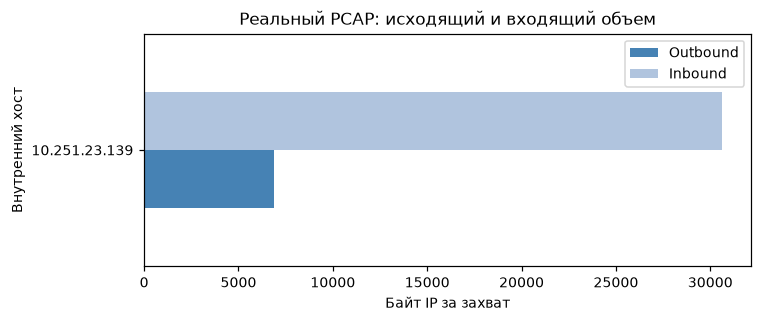

In [4]:
real_top = real_boundary.head(10).sort_values("out_bytes")
ax = real_top[["out_bytes", "in_bytes"]].plot.barh(
    figsize=(7, 3), color=["steelblue", "lightsteelblue"])
ax.set_xlabel("Байт IP за захват")
ax.set_ylabel("Внутренний хост")
ax.set_title("Реальный PCAP: исходящий и входящий объем")
ax.legend(["Outbound", "Inbound"])
plt.tight_layout()
plt.show()

Получено 90 потоков из 370 IPv4-пакетов. У 10.251.23.139 исходящий объем —
6 895 байт, входящий — 30 641 байт, Out/In = 0,23: преобладает загрузка данных.
Дамп запуска роутера со скачками часов не подходит для устойчивого baseline.

### Учебный дамп

| Хост | Активность |
| :--- | :--- |
| 10.0.0.21–30 | Обычные веб-сеансы. |
| 10.0.0.50 | Разрешенная резервная передача. |
| 10.0.0.66 | Крупная передача на неразрешенный адрес. |
| 10.0.0.77 | SYN на 25 портов. |
| 10.0.0.35 | Мониторинг 12 портов с обменом данными. |
| 10.0.0.47 | Повторные SYN на один порт. |
| Четыре внешних источника | 400 незавершенных соединений к 10.0.0.10:443. |
| 10.0.0.21 → 10.0.0.20 | 120 успешных соединений. |

Внешние адреса учебные. Пакеты только записываются в файл.

In [5]:
packets_out = []
START = 1_700_000_040.0

def emit(t, src, dst, sport, dport, flags, seq=1000, ack=0, payload=b""):
    packet = (Ether(src="02:00:00:00:00:01", dst="02:00:00:00:00:02") /
              IP(src=src, dst=dst) /
              TCP(sport=sport, dport=dport, flags=flags, seq=seq, ack=ack))
    if payload:
        packet /= Raw(load=payload)
    packet.time = t
    packets_out.append(packet)

def session(t, client, server, sport, dport=443, upload=1, download=1, chunk=400):
    cseq, sseq = 1000, 5000
    def send(reverse, flags, data=b""):
        nonlocal t, cseq, sseq
        if reverse:
            emit(t, server, client, dport, sport, flags, sseq, cseq, data)
            sseq += len(data) + int("S" in flags or "F" in flags)
        else:
            emit(t, client, server, sport, dport, flags, cseq, sseq, data)
            cseq += len(data) + int("S" in flags or "F" in flags)
        t += 0.001
    emit(t, client, server, sport, dport, "S", cseq, 0)
    cseq += 1
    t += 0.001
    send(True, "SA")
    send(False, "A")
    for _ in range(upload):
        send(False, "PA", b"u" * chunk)
        send(True, "A")
    for _ in range(download):
        send(True, "PA", b"d" * chunk)
        send(False, "A")
    send(False, "FA")
    send(True, "A")
    send(True, "FA")
    send(False, "A")

for minute in range(11):
    base = START + minute * 60
    for i in range(10):
        session(base + 2 + i, f"10.0.0.{21+i}", "203.0.113.10", 40000 + minute)
    session(base + 15, "10.0.0.50", "203.0.113.50", 45000 + minute,
            upload=250, download=1, chunk=1200)

current_start = START + 600
session(current_start + 20, "10.0.0.66", "198.51.100.200", 46000,
        upload=200, download=0, chunk=1200)
for i in range(25):
    t, port = current_start + 22 + i * 0.02, 20 + i
    emit(t, "10.0.0.77", "10.0.0.10", 47000 + i, port, "S")
    emit(t + 0.001, "10.0.0.10", "10.0.0.77", port, 47000 + i, "RA")
for i, port in enumerate([22, 80, 443, 3000, 5044, 5601, 8080, 9090, 9100, 9200, 9300, 9995]):
    session(current_start + 24 + i * 0.02, "10.0.0.35", "10.0.0.10", 48000 + i, port)
for i in range(8):
    emit(current_start + 26 + i * 0.5, "10.0.0.47", "10.0.0.10", 49000, 8080, "S")
for i in range(400):
    source = f"198.51.100.{10 + i % 4}"
    t = current_start + 32 + i * 0.02
    emit(t, source, "10.0.0.10", 50000 + i, 443, "S")
    emit(t + 0.001, "10.0.0.10", source, 443, 50000 + i, "SA", 5000, 1001)
for i in range(120):
    session(current_start + 43 + i * 0.02, "10.0.0.21", "10.0.0.20", 55000 + i)

packets_out.sort(key=lambda p: float(p.time))
wrpcap(str(TEST_FILE), packets_out)
test_df, test_info = pcap_to_flows(TEST_FILE)
train_df = test_df[test_df.start_time < current_start].copy()
current_df = test_df[test_df.start_time >= current_start].copy()
print(f"{len(packets_out)} пакетов записано в {TEST_FILE}")
display(pd.DataFrame([test_info], index=[TEST_FILE.name]))
print(f"Обучение: {len(train_df)} потоков; проверка: {len(current_df)} потоков")
test_df.to_csv("flows_test.csv", index=False)

9526 пакетов записано в flow_test_traffic.pcap

,frames,ipv4_packets,skipped,flows,time_rollbacks
flow_test_traffic.pcap,9526,9526,0,680,0


Обучение: 110 потоков; проверка: 570 потоков

### Топ-10 и асимметрия

Baseline — средний Outbound на хост за минуту по первым 10 минутам, включая нулевые интервалы.
Проверяю следующую минуту: Outbound > 3 × baseline, Out/In > 3 и неразрешенное направление.

In [6]:
HOSTS = [f"10.0.0.{i}" for i in range(21, 31)] + [
    "10.0.0.50", "10.0.0.35", "10.0.0.47", "10.0.0.66",
    "10.0.0.77", "10.0.0.10", "10.0.0.20"]
ALLOWED_PEERS = {"203.0.113.10", "203.0.113.50"}

train_by_minute = []
for minute in range(10):
    part = train_df[(train_df.start_time >= START + minute * 60) &
                    (train_df.start_time < START + (minute + 1) * 60)]
    train_by_minute.append(boundary_traffic(part, HOSTS).out_bytes.reindex(HOSTS))
baseline_by_host = pd.concat(train_by_minute, axis=1).mean(axis=1)
baseline_network = baseline_by_host.mean()
baseline_activity = source_activity(train_df).total_bytes.sum() / (len(HOSTS) * 10)
print(f"Baseline двунаправленной активности: {baseline_activity:,.2f} байт/(хост·мин)")
print(f"Baseline Outbound: {baseline_network:,.2f} байт/(хост·мин)")
print(f"Порог 3 × baseline: {3 * baseline_network:,.2f} байт за минуту")

activity = source_activity(current_df)
print("Топ-10 источников по bidirectional_bytes:")
display(activity.head(10).round(2))

traffic = boundary_traffic(current_df, HOSTS)
traffic["out_in"] = np.where(traffic.in_bytes > 0,
    traffic.out_bytes / traffic.in_bytes.replace(0, np.nan),
    np.where(traffic.out_bytes > 0, np.inf, np.nan))
traffic["baseline_out"] = baseline_by_host
traffic["network_multiple"] = traffic.out_bytes / baseline_network
unknown = current_df[current_df.src_ip.map(internal) &
    ~current_df.dst_ip.map(internal) & current_df.dst_ip.map(unicast) &
    ~current_df.dst_ip.isin(ALLOWED_PEERS)].groupby("src_ip").forward_bytes.sum()
traffic["unapproved_out"] = unknown.reindex(traffic.index, fill_value=0)
traffic["candidate"] = ((traffic.out_bytes > 3 * baseline_network) &
                        (traffic.out_in > 3) & (traffic.unapproved_out > 0))
print("Топ-10 по Outbound:")
display(traffic.head(10).round(2))
print("Кандидаты на проверку:")
display(traffic[traffic.candidate].round(2))

Baseline двунаправленной активности: 19,644.71 байт/(хост·мин)

Baseline Outbound: 18,623.53 байт/(хост·мин)

Порог 3 × baseline: 55,870.59 байт за минуту

Топ-10 источников по bidirectional_bytes:

,total_bytes,total_packets,total_flows,bytes_per_flow,bytes_per_packet
src_ip,,,,,
10.0.0.50,321560,509,1,"321,560.00",631.75
10.0.0.66,256280,407,1,"256,280.00",629.68
10.0.0.21,150040,1331,121,"1,240.00",112.73
10.0.0.35,14880,132,12,"1,240.00",112.73
10.0.0.77,2000,50,25,80.00,40.00
10.0.0.22,1240,11,1,"1,240.00",112.73
10.0.0.23,1240,11,1,"1,240.00",112.73
10.0.0.27,1240,11,1,"1,240.00",112.73
10.0.0.26,1240,11,1,"1,240.00",112.73


Топ-10 по Outbound:

,out_bytes,in_bytes,flows,packets,out_in,baseline_out,network_multiple,unapproved_out,candidate
host,,,,,,,,,
10.0.0.50,310200,11360,1,509,27.31,"310,200.00",16.66,0,False
10.0.0.66,248160,8120,1,407,30.56,0.00,13.33,248160,True
10.0.0.10,16000,16000,400,800,1.00,0.00,0.86,0,False
10.0.0.21,640,600,1,11,1.07,640.00,0.03,0,False
10.0.0.22,640,600,1,11,1.07,640.00,0.03,0,False
10.0.0.26,640,600,1,11,1.07,640.00,0.03,0,False
10.0.0.23,640,600,1,11,1.07,640.00,0.03,0,False
10.0.0.24,640,600,1,11,1.07,640.00,0.03,0,False
10.0.0.25,640,600,1,11,1.07,640.00,0.03,0,False


Кандидаты на проверку:

,out_bytes,in_bytes,flows,packets,out_in,baseline_out,network_multiple,unapproved_out,candidate
host,,,,,,,,,
10.0.0.66,248160,8120,1,407,30.56,0.00,13.33,248160,True


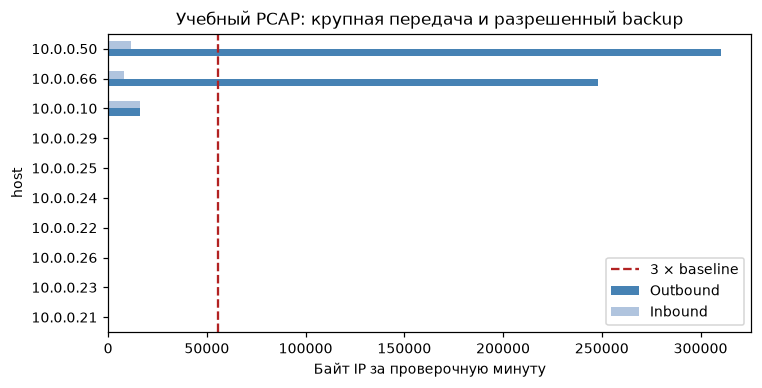

In [7]:
ax = traffic.head(10).sort_values("out_bytes")[["out_bytes", "in_bytes"]].plot.barh(
    figsize=(7, 3.6), color=["steelblue", "lightsteelblue"])
ax.axvline(3 * baseline_network, color="firebrick", linestyle="--", label="3 × baseline")
ax.set_xlabel("Байт IP за проверочную минуту")
ax.set_title("Учебный PCAP: крупная передача и разрешенный backup")
ax.legend(["3 × baseline", "Outbound", "Inbound"])
plt.tight_layout()
plt.show()

In [8]:
suspect_upload = traffic.loc["10.0.0.66"]
backup = traffic.loc["10.0.0.50"]
print(f"10.0.0.66: Outbound {suspect_upload.out_bytes:,.0f} байт, "
      f"Inbound {suspect_upload.in_bytes:,.0f}, Out/In {suspect_upload.out_in:.2f}, "
      f"превышение среднего {suspect_upload.network_multiple:.2f} раза.")
print(f"10.0.0.50: Outbound {backup.out_bytes:,.0f} байт; "
      f"baseline этого хоста {backup.baseline_out:,.0f} байт/мин; "
      f"кандидат: {bool(backup.candidate)}.")

10.0.0.66: Outbound 248,160 байт, Inbound 8,120, Out/In 30.56, превышение среднего 13.33 раза.

10.0.0.50: Outbound 310,200 байт; baseline этого хоста 310,200 байт/мин; кандидат: False.

### Вывод

**10.0.0.66 → 198.51.100.200:443**: исходящий объем 248 160 байт,
Out/In = 30,56, превышение baseline в 13,33 раза.
У **10.0.0.50** объем больше, но соответствует обычной резервной передаче.

## Задание 2. Обнаружение сложных аномалий

### Сканирование

Условия за минуту: **уникальных портов > 10 И среднее число пакетов на поток < 5**.
Учитываю TCP-потоки, начавшиеся с SYN без ACK.

In [9]:
def analyze_port_scanning(df, threshold_unique_ports=10, threshold_packets=5):
    candidates = df[(df.protocol == "TCP") & df.initiator_syn].groupby("src_ip").agg(
        unique_ports=("dst_port", "nunique"),
        total_flows=("dst_port", "size"),
        mean_packets=("bidirectional_packets", "mean"))
    candidates["ports_only"] = candidates.unique_ports > threshold_unique_ports
    candidates["combined"] = (candidates.ports_only &
                               (candidates.mean_packets < threshold_packets))
    return candidates.sort_values("unique_ports", ascending=False)

scan_table = analyze_port_scanning(current_df)
display(scan_table.round(2))
print("Срабатывания комбинированного правила:")
display(scan_table[scan_table.combined].round(2))
print("Реальный PCAP, те же условия за весь файл (описательная проверка):")
real_scan = analyze_port_scanning(real_df)
display(real_scan[real_scan.combined].round(2))

,unique_ports,total_flows,mean_packets,ports_only,combined
src_ip,,,,,
10.0.0.77,25,25,2.00,True,True
10.0.0.35,12,12,11.00,True,False
10.0.0.21,1,121,11.00,False,False
10.0.0.23,1,1,11.00,False,False
10.0.0.22,1,1,11.00,False,False
10.0.0.26,1,1,11.00,False,False
10.0.0.24,1,1,11.00,False,False
10.0.0.27,1,1,11.00,False,False
10.0.0.28,1,1,11.00,False,False


Срабатывания комбинированного правила:

,unique_ports,total_flows,mean_packets,ports_only,combined
src_ip,,,,,
10.0.0.77,25,25,2.00,True,True


Реальный PCAP, те же условия за весь файл (описательная проверка):

,unique_ports,total_flows,mean_packets,ports_only,combined
src_ip,,,,,


**10.0.0.77**: 25 портов, по 2 пакета — правило сработало.
**10.0.0.35**: 12 портов, по 11 пакетов — мониторинг исключен.
У **10.0.0.47** повторы SYN остаются одним потоком к одному порту.

Сканеру обычно достаточно SYN и ответа SYN-ACK/RST, поэтому пакетов мало.
Короткие проверки доступности могут давать похожую картину.

### SYN-flood

Плотность **D = flows / packets**, среднее число пакетов **P = 1 / D**.
При коротких потоках D растет. Условия: **потоков ≥ 100, P < 5**,
доля незавершенных рукопожатий > 90%.

In [10]:
def analyze_syn_flood(df, min_flows=100, max_mean_packets=5):
    tcp = df[(df.protocol == "TCP") & df.initiator_syn].copy()
    table = tcp.groupby("dst_ip").agg(
        total_flows=("src_ip", "size"),
        total_packets=("bidirectional_packets", "sum"),
        source_hosts=("src_ip", "nunique"),
        handshakes=("handshake_seen", "sum"))
    table["mean_packets"] = table.total_packets / table.total_flows
    table["density"] = table.total_flows / table.total_packets
    table["incomplete_share"] = 1 - table.handshakes / table.total_flows
    table["flow_candidate"] = ((table.total_flows >= min_flows) &
                                (table.mean_packets < max_mean_packets))
    table["syn_candidate"] = table.flow_candidate & (table.incomplete_share > 0.9)
    return table.sort_values("total_flows", ascending=False)

flood_table = analyze_syn_flood(current_df)
display(flood_table.round(3))
print("Наиболее подозрительные назначения:")
display(flood_table[flood_table.syn_candidate].round(3))
print("Реальный PCAP, проверка тех же порогов за файл:")
real_flood = analyze_syn_flood(real_df)
display(real_flood[real_flood.syn_candidate].round(3))

,total_flows,total_packets,source_hosts,handshakes,mean_packets,density,incomplete_share,flow_candidate,syn_candidate
dst_ip,,,,,,,,,
10.0.0.10,438,990,7,12,2.26,0.44,0.97,True,True
10.0.0.20,120,1320,1,120,11.00,0.09,0.00,False,False
203.0.113.10,10,110,10,10,11.00,0.09,0.00,False,False
198.51.100.200,1,407,1,1,407.00,0.00,0.00,False,False
203.0.113.50,1,509,1,1,509.00,0.00,0.00,False,False


Наиболее подозрительные назначения:

,total_flows,total_packets,source_hosts,handshakes,mean_packets,density,incomplete_share,flow_candidate,syn_candidate
dst_ip,,,,,,,,,
10.0.0.10,438,990,7,12,2.26,0.44,0.97,True,True


Реальный PCAP, проверка тех же порогов за файл:

,total_flows,total_packets,source_hosts,handshakes,mean_packets,density,incomplete_share,flow_candidate,syn_candidate
dst_ip,,,,,,,,,


In [11]:
port_stats = current_df[(current_df.protocol == "TCP") & current_df.initiator_syn].groupby(
    ["dst_ip", "dst_port"]).agg(
        flows=("src_ip", "size"), packets=("bidirectional_packets", "sum"),
        sources=("src_ip", "nunique"), completed=("handshake_seen", "sum"))
port_stats["packets_per_flow"] = port_stats.packets / port_stats.flows
display(port_stats.sort_values("flows", ascending=False).head(5).round(2))

target = flood_table.loc["10.0.0.10"]
print(f"10.0.0.10: {target.total_flows:.0f} потоков, "
      f"{target.mean_packets:.3f} пакета/поток, плотность {target.density:.3f}, "
      f"незавершенных {target.incomplete_share:.1%}.")

flows  packets  sources  completed  packets_per_flow
dst_ip       dst_port                                                      
10.0.0.10    443         401      811        5          1              2.02
10.0.0.20    443         120     1320        1        120             11.00
203.0.113.10 443          10      110       10         10             11.00
10.0.0.10    22            2       13        2          1              6.50
             8080          2       19        2          1              9.50

10.0.0.10: 438 потоков, 2.260 пакета/поток, плотность 0.442, незавершенных 97.3%.

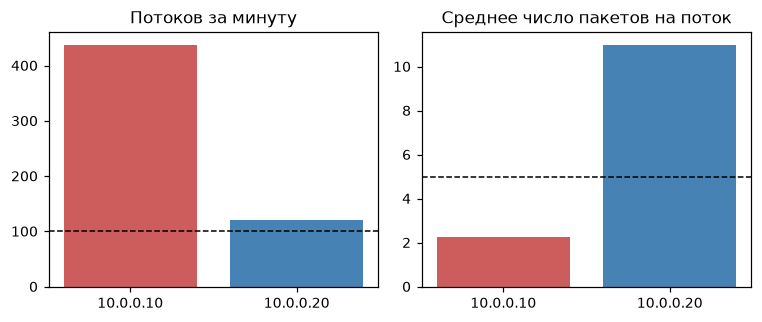

In [12]:
selected = flood_table.loc[["10.0.0.10", "10.0.0.20"]]
fig, axes = plt.subplots(1, 2, figsize=(7, 3))
axes[0].bar(selected.index, selected.total_flows, color=["indianred", "steelblue"])
axes[0].axhline(100, color="black", linestyle="--", linewidth=1)
axes[0].set_title("Потоков за минуту")
axes[1].bar(selected.index, selected.mean_packets, color=["indianred", "steelblue"])
axes[1].axhline(5, color="black", linestyle="--", linewidth=1)
axes[1].set_title("Среднее число пакетов на поток")
plt.tight_layout()
plt.show()

### Вывод

Подозрительная цель — **10.0.0.10**: 438 потоков, 2,26 пакета на поток,
97,3% незавершенных соединений. На порт 443 приходится 400 подозрительных
потоков и один сеанс мониторинга.
У **10.0.0.20** 120 успешных соединений по 11 пакетов — правило не сработало.
В реальном дампе заданные признаки сканирования и SYN-flood не обнаружены.

## Проверка результатов

In [13]:
assert set(traffic.index[traffic.candidate]) == {"10.0.0.66"}
assert set(scan_table.index[scan_table.combined]) == {"10.0.0.77"}
assert bool(scan_table.loc["10.0.0.35", "ports_only"])
assert not bool(scan_table.loc["10.0.0.35", "combined"])
assert set(flood_table.index[flood_table.syn_candidate]) == {"10.0.0.10"}
assert not bool(flood_table.loc["10.0.0.20", "flow_candidate"])
assert not real_scan.combined.any() and not real_flood.syn_candidate.any()
assert np.allclose(flood_table.density * flood_table.mean_packets, 1)
assert len(train_df) == 110 and len(current_df) == 570
print("Проверки пройдены: объем и направления, сканер/мониторинг, SYN/обычные сеансы.")

Проверки пройдены: объем и направления, сканер/мониторинг, SYN/обычные сеансы.

## Заключение

Flow-анализ выделил крупную передачу, сканирование и незавершенные SYN-соединения.
Для расследования сопоставил бы адреса и время с событиями Suricata в Kibana
и процессами в BI.Zone EDR, проверил расписание мониторинга и резервного копирования.
Срабатывание правила само по себе не подтверждает атаку.

## Контрольные вопросы

**1. Как работают Flow-протоколы и чем отличаются от полного захвата пакетов?**

Экспортер группирует пакеты в потоки и передает коллектору адреса, порты,
время и счетчики. Flow показывает структуру и объем соединений;
полный PCAP дополнительно сохраняет содержимое пакетов, но занимает больше места.

**2. Чем отличаются NetFlow, IPFIX и sFlow?**

NetFlow v5 использует фиксированный формат IPv4, v9 — расширяемые шаблоны.
IPFIX — открытый стандарт с шаблонами и реестром полей.
sFlow передает выборки заголовков пакетов и счетчики интерфейсов.

**3. Плюсы и минусы сэмплированного и несэмплированного трафика.**

Без выборки учитываются все наблюдаемые пакеты, но выше нагрузка.
Сэмплирование экономит ресурсы, однако может пропустить короткие соединения
и малые передачи. NetFlow/IPFIX также могут использовать выборку.

**4. Как Flow используется в кибербезопасности?**

Для поиска DDoS, сканирования, эксфильтрации и C&C-связи по объему,
частоте и направлениям соединений. События проверяются по журналам SIEM/EDR:
похожую активность могут создавать мониторинг и резервное копирование.

**5. Как Flow связан с сетевой телеметрией?**

Flow — вид телеметрии: устройства автоматически передают измерения
сетевых коммуникаций. По ним строят baseline, графики нагрузки и оповещения.

**6. Какое отношение Total Bytes / Total Flows указывает на передачу файла?**

Высокое число байтов на поток характерно для крупных передач.
При сканировании потоков много, а байтов в каждом мало.
Сам показатель не отличает резервную передачу от эксфильтрации.

**7. Чем отличаются bidirectional_packets и packetDeltaCount и как это влияет на анализ DDoS?**

`bidirectional_packets` в скрипте суммирует пакеты обоих направлений.
`packetDeltaCount` в IPFIX считает пакеты одного потока с предыдущего отчета;
в NetFlow v9 соответствующее поле называется `IN_PKTS`.
При DDoS-анализе нужно отделять пакеты к цели от ее ответов, иначе входящая
нагрузка будет завышена. Пороги сравнивают при одинаковых направлениях,
тайм-аутах и условиях сэмплирования.